# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import glob
import os
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)
from lightgbm import LGBMRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-16-used-car-valuation/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-16-used-car-valuation\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

matches = glob.glob("../data/raw/**/*v3*.csv", recursive=True)
CSV_PATH = matches[0] if matches else "../data/raw/Car details v3.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-16-used-car-valuation\src
Raw Dataset Shape : 8,128 rows, 13 columns


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


# EDA 1: Schema, Seller-Type Duplicate Distortion & String-Unit Audit

In [2]:
dup_count = df_raw.duplicated().sum()
print(f"Exact Duplicate Rows : {dup_count:,} ({dup_count / len(df_raw):.2%}) -> Leaves {len(df_raw) - dup_count:,} unique cars")

# Prove how duplicates disproportionately inflate Dealer / Trustmark Dealer counts & mean price
dup_audit = (
    df_raw.assign(is_dup=df_raw.duplicated())
    .groupby("seller_type")
    .agg(Total_Rows=("is_dup", "count"), Duplicate_Rows=("is_dup", "sum"), Raw_Mean_Price=("selling_price", "mean"))
)
dup_audit["Duplicate_Pct (%)"] = (dup_audit["Duplicate_Rows"] / dup_audit["Total_Rows"] * 100).round(2)
display(dup_audit.round(2))

# Audit nulls, dtypes, and string-encoded numeric columns
audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Null_Count": df_raw[col].isnull().sum(),
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].dropna().unique()[:3]),
    })
display(pd.DataFrame(audit_records))

Exact Duplicate Rows : 1,202 (14.79%) -> Leaves 6,926 unique cars


,Total_Rows,Duplicate_Rows,Raw_Mean_Price,Duplicate_Pct (%)
seller_type,,,,
Dealer,1126,445,1443493.75,39.52
Individual,6766,548,498561.23,8.10
Trustmark Dealer,236,209,801838.98,88.56


,Column,Dtype,Null_Count,Unique_Values,Sample_Values
0,name,str,0,2058,<StringArray>\n[ 'Maruti Swift Dzire VDI'...
1,year,int64,0,29,[2014 2006 2010]
2,selling_price,int64,0,677,[450000 370000 158000]
3,km_driven,int64,0,921,[145500 120000 140000]
4,fuel,str,0,4,"<StringArray>\n['Diesel', 'Petrol', 'LPG']\nLe..."
5,seller_type,str,0,3,"<StringArray>\n['Individual', 'Dealer', 'Trust..."
6,transmission,str,0,2,"<StringArray>\n['Manual', 'Automatic']\nLength..."
7,owner,str,0,5,"<StringArray>\n['First Owner', 'Second Owner',..."
8,mileage,str,221,393,"<StringArray>\n['23.4 kmpl', '21.14 kmpl', '17..."
9,engine,str,221,121,"<StringArray>\n['1248 CC', '1498 CC', '1497 CC..."


# EDA 2: Target Skewness, Brand Depreciation & Visual Dashboard

Unique-Car Mean Price : ₹517,270.68 (vs Raw Mean: ₹638,271.81)
Raw Price Skewness    : 5.57 | Log1p Skewness : -0.16


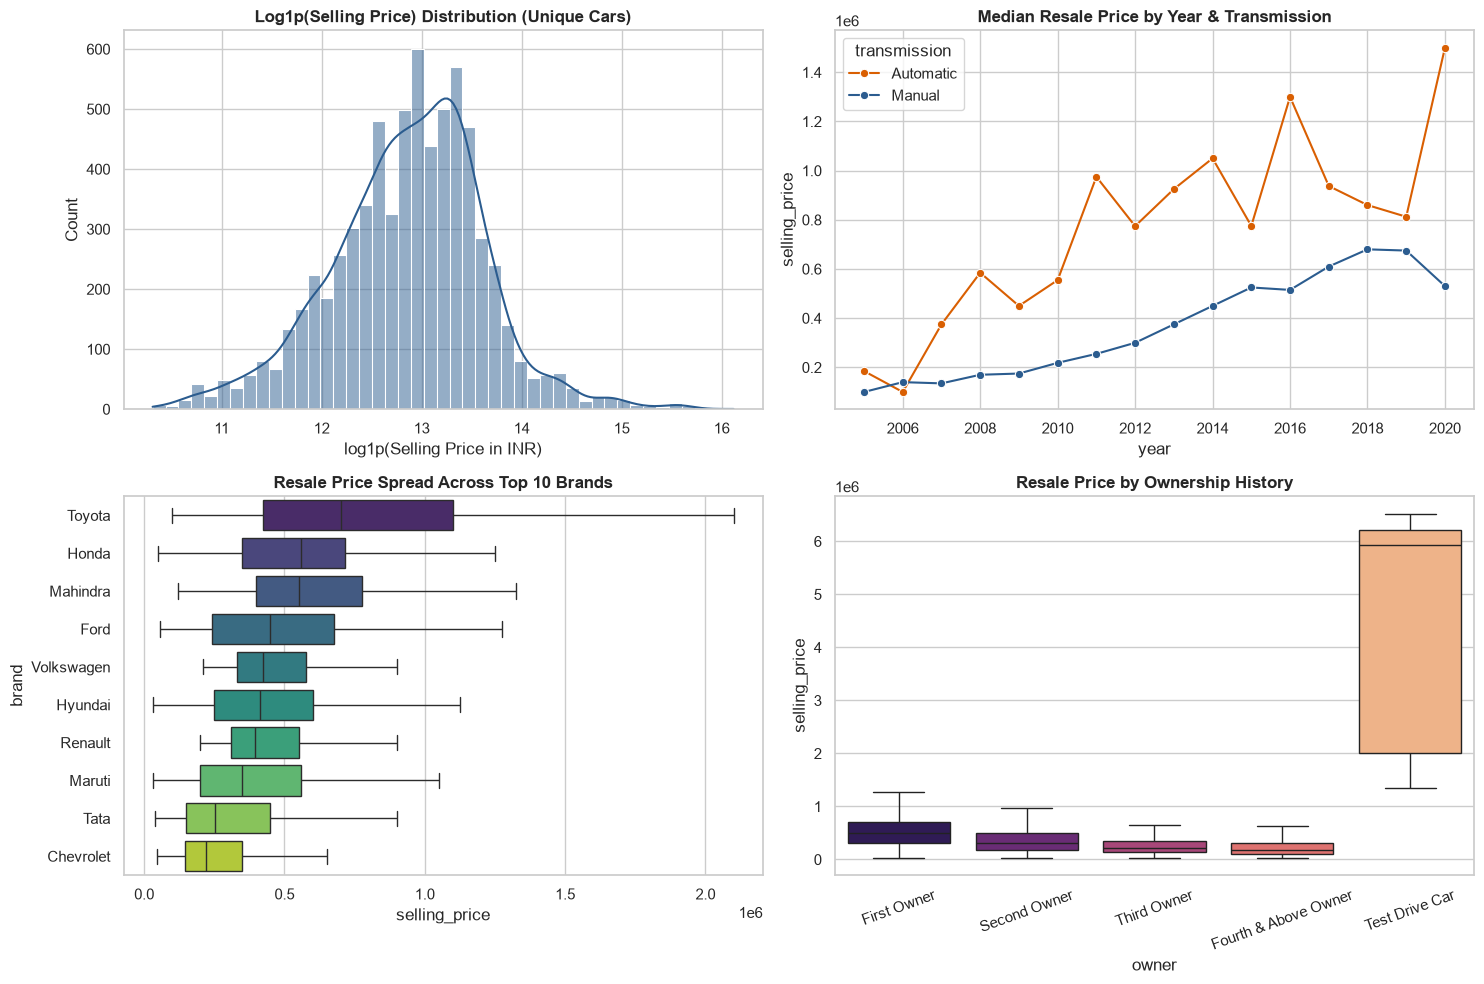

In [3]:
df_eda = df_raw.drop_duplicates().copy()
df_eda["brand"] = df_eda["name"].astype(str).str.split().str[0]

print(f"Unique-Car Mean Price : ₹{df_eda['selling_price'].mean():,.2f} (vs Raw Mean: ₹{df_raw['selling_price'].mean():,.2f})")
print(f"Raw Price Skewness    : {df_eda['selling_price'].skew():.2f} | Log1p Skewness : {np.log1p(df_eda['selling_price']).skew():.2f}")

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Log-Transformed Selling Price Distribution
sns.histplot(np.log1p(df_eda["selling_price"]), bins=45, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].set_title("Log1p(Selling Price) Distribution (Unique Cars)", fontweight="bold")
axes[0, 0].set_xlabel("log1p(Selling Price in INR)")

# Plot 2: Depreciation Curve by Manufacturing Year & Transmission
year_trend = df_eda[df_eda["year"] >= 2005].groupby(["year", "transmission"])["selling_price"].median().reset_index()
sns.lineplot(data=year_trend, x="year", y="selling_price", hue="transmission", marker="o", palette=["#d95f02", "#2b5c8f"], ax=axes[0, 1])
axes[0, 1].set_title("Median Resale Price by Year & Transmission", fontweight="bold")

# Plot 3: Median Price Across Top 10 Most Frequent Brands
top10_brands = df_eda["brand"].value_counts().nlargest(10).index
brand_df = df_eda[df_eda["brand"].isin(top10_brands)]
brand_order = brand_df.groupby("brand")["selling_price"].median().sort_values(ascending=False).index
sns.boxplot(data=brand_df, x="selling_price", y="brand", order=brand_order, palette="viridis", showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Resale Price Spread Across Top 10 Brands", fontweight="bold")

# Plot 4: Impact of Ownership History on Selling Price
owner_order = ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner", "Test Drive Car"]
avail_owners = [o for o in owner_order if o in df_eda["owner"].unique()]
sns.boxplot(data=df_eda, x="owner", y="selling_price", order=avail_owners, palette="magma", showfliers=False, ax=axes[1, 1])
axes[1, 1].set_title("Resale Price by Ownership History", fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("outputs/eda_used_car_valuation.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning & Regex Numeric Extraction

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 1,202 exact duplicate rows (especially 209 repeated Trustmark Dealer listings) to prevent train-test leakage.
2. Parse numeric values from dirty unit strings using safe regex extraction:
   - 'mileage'   : extract float (handles 'kmpl' and 'km/kg', converts 0.0 placeholders to NaN)
   - 'engine'    : extract CC integer/float
   - 'max_power' : extract BHP float (safely turns bare ' bhp' strings into NaN instead of crashing)
   - 'torque'    : extract primary Nm torque value (converting kgm -> Nm via * 9.80665 when 'kgm' appears)
3. Extract 'brand' from 'name' before dropping the raw 'name' and 'torque' text columns.
"""
df_clean = df_raw.drop_duplicates().reset_index(drop=True)

def extract_first_float(series):
    extracted = series.astype(str).str.extract(r"(\d+\.?\d*)")[0]
    return pd.to_numeric(extracted, errors="coerce")

def parse_torque_nm(val):
    if pd.isna(val):
        return np.nan
    s = str(val).lower()
    m = re.search(r"(\d+\.?\d*)", s)
    if not m:
        return np.nan
    num = float(m.group(1))
    return num * 9.80665 if "kgm" in s else num

df_clean["mileage_num"] = extract_first_float(df_clean["mileage"])
df_clean.loc[df_clean["mileage_num"] == 0, "mileage_num"] = np.nan
df_clean["engine_cc"] = extract_first_float(df_clean["engine"])
df_clean["max_power_bhp"] = extract_first_float(df_clean["max_power"])
df_clean["torque_nm"] = df_clean["torque"].apply(parse_torque_nm)

df_clean["brand"] = df_clean["name"].astype(str).str.split().str[0]
df_clean.drop(columns=["name", "mileage", "engine", "max_power", "torque"], inplace=True)

print(f"Cleaned Unique Cars: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
print("Missing values remaining after regex parsing (to be imputed leak-free inside pipeline):")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Cleaned Unique Cars: 6,926 rows, 13 columns
Missing values remaining after regex parsing (to be imputed leak-free inside pipeline):
seats            208
mileage_num      223
engine_cc        208
max_power_bhp    206
torque_nm        209
dtype: int64


# Automotive Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Vehicle age relative to dataset reference year (2020) & usage intensity
ref_year = df_feat["year"].max()
df_feat["vehicle_age"] = np.maximum(ref_year - df_feat["year"], 0)
df_feat["km_per_year"] = df_feat["km_driven"] / (df_feat["vehicle_age"] + 1.0)
df_feat["log_km_driven"] = np.log1p(df_feat["km_driven"])

# 2. Power-to-displacement efficiency & luxury automatic interaction
df_feat["power_per_liter"] = df_feat["max_power_bhp"] / (df_feat["engine_cc"] / 1000.0 + 1e-5)
df_feat["is_automatic"] = (df_feat["transmission"] == "Automatic").astype(int)

X = df_feat.drop(columns=["selling_price"])
y = df_feat["selling_price"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df_feat["transmission"]
)

# Group rare brands (< 1% prevalence in X_train) strictly inside training fold
brand_freq = X_train["brand"].value_counts(normalize=True)
common_brands = brand_freq[brand_freq >= 0.01].index.tolist()
X_train["brand"] = X_train["brand"].where(X_train["brand"].isin(common_brands), "Other_Brand")
X_test["brand"] = X_test["brand"].where(X_test["brand"].isin(common_brands), "Other_Brand")

ordinal_cols = ["owner"]
nominal_cols = ["fuel", "seller_type", "transmission", "brand"]
num_cols = [c for c in X_train.columns if c not in ordinal_cols + nominal_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(
            categories=[["Test Drive Car", "First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]],
            handle_unknown="use_encoded_value", unknown_value=-1
        )),
    ]), ordinal_cols),
    ("nom", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), nominal_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (5540, 17) | Test Set: (1386, 17)


# Model Benchmarking (Log-Target Ridge vs. Log-Target LightGBM)

In [6]:
models = {
    "Log-Target Ridge Regression (Baseline)": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("model", Ridge(alpha=5.0, random_state=42)),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    "Log-Target LightGBM (Used Car AVM)": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("model", LGBMRegressor(
                n_estimators=500,
                learning_rate=0.04,
                num_leaves=31,
                max_depth=7,
                subsample=0.8,
                colsample_bytree=0.8,
                n_jobs=-1,
                random_state=42,
                verbose=-1,
            )),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
}

best_model, best_mape = None, float("inf")

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = np.maximum(model.predict(X_test), 0.0)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    print(f"\n---> {name}")
    print(f"MAE : ₹{mae:,.2f} | RMSE : ₹{rmse:,.2f} | MAPE : {mape:.2f}% | R² Score : {r2:.4f}")

    if mape < best_mape:
        best_mape = mape
        best_model = model

joblib.dump(best_model, "outputs/best_used_car_model.joblib")


---> Log-Target Ridge Regression (Baseline)
MAE : ₹105,107.23 | RMSE : ₹227,665.92 | MAPE : 21.60% | R² Score : 0.8223

---> Log-Target LightGBM (Used Car AVM)
MAE : ₹75,377.16 | RMSE : ₹147,257.29 | MAPE : 16.70% | R² Score : 0.9257


['outputs/best_used_car_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

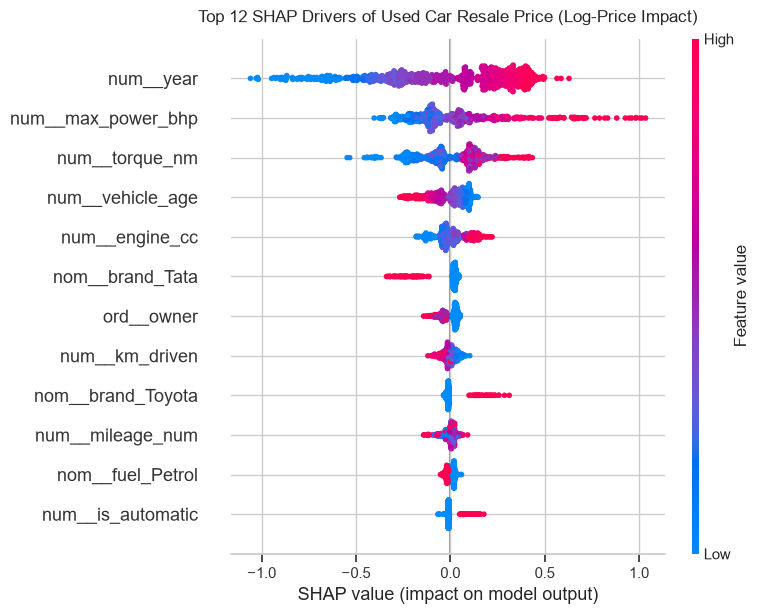

In [7]:
lgbm_fitted_pipe = models["Log-Target LightGBM (Used Car AVM)"].regressor_

X_test_sample = X_test.sample(min(800, len(X_test)), random_state=42)
X_test_transformed = lgbm_fitted_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_fitted_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_fitted_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Used Car Resale Price (Log-Price Impact)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_used_car_valuation.png", dpi=150)
plt.show()

# Error Analysis Audit: Top 5 Worst Valuation Errors (Residual Inspection)

In [8]:
lgbm_avm = models["Log-Target LightGBM (Used Car AVM)"]
y_pred_lgbm = np.maximum(lgbm_avm.predict(X_test), 0.0)

error_df = X_test[["brand", "year", "km_driven", "fuel", "transmission", "seller_type", "owner", "max_power_bhp"]].copy()
error_df["Actual_Price_INR"] = y_test
error_df["Predicted_Price_INR"] = y_pred_lgbm
error_df["Abs_Error_INR"] = np.abs(error_df["Actual_Price_INR"] - error_df["Predicted_Price_INR"])
error_df["Pct_Error (%)"] = (error_df["Abs_Error_INR"] / error_df["Actual_Price_INR"]) * 100

print("Top 5 Largest Absolute Valuation Errors (INR):")
display(error_df.sort_values(by="Abs_Error_INR", ascending=False).head(5).round(2))

print("\nTop 5 Largest Percentage Valuation Errors (%):")
display(error_df.sort_values(by="Pct_Error (%)", ascending=False).head(5).round(2))

Top 5 Largest Absolute Valuation Errors (INR):


,brand,year,km_driven,fuel,transmission,seller_type,owner,max_power_bhp,Actual_Price_INR,Predicted_Price_INR,Abs_Error_INR,Pct_Error (%)
5348,Toyota,2014,60000,Diesel,Automatic,Individual,First Owner,170.30,3500000,1533114.96,1966885.04,56.20
3132,Volkswagen,2011,50000,Diesel,Manual,Individual,Second Owner,NaN,2150000,290543.07,1859456.93,86.49
138,Other_Brand,2017,27000,Diesel,Automatic,Dealer,First Owner,NaN,2150000,635654.94,1514345.06,70.43
1003,Other_Brand,2013,56000,Diesel,Automatic,Dealer,First Owner,241.00,3750000,2573511.05,1176488.95,31.37
132,Other_Brand,2019,20000,Petrol,Automatic,Dealer,First Owner,214.56,5150000,4087387.44,1062612.56,20.63



Top 5 Largest Percentage Valuation Errors (%):


,brand,year,km_driven,fuel,transmission,seller_type,owner,max_power_bhp,Actual_Price_INR,Predicted_Price_INR,Abs_Error_INR,Pct_Error (%)
6337,Tata,2008,60000,Diesel,Manual,Individual,Second Owner,68.00,45000,140295.03,95295.03,211.77
6631,Tata,2012,82507,Diesel,Manual,Dealer,First Owner,138.03,132000,391631.28,259631.28,196.69
4111,Skoda,2006,120000,Petrol,Manual,Individual,Third Owner,149.50,100000,263212.48,163212.48,163.21
6338,Ford,2006,201000,Diesel,Manual,Individual,First Owner,68.00,55000,144269.37,89269.37,162.31
5747,Volkswagen,2020,50000,Diesel,Manual,Individual,First Owner,88.50,260000,679985.38,419985.38,161.53
